# Análise e visualização de vendas
Gabriel das Chagas Silva | Anhanguera | Engenharia de Software

Disciplina: Linguagem de Programação. Notebook compatível com Google Colab. Resultados desta entrega executados localmente em Python em 13/10/2026.

No Colab: Arquivo > Fazer upload de notebook; depois Ambiente de execução > Executar tudo. Se faltar uma biblioteca, instale matplotlib, seaborn, pandas, scikit-learn e tensorflow com pip.

## Conectar ao SQLite e inserir a amostra fornecida pelo roteiro

In [1]:
import sqlite3
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dados = [
    ('2023-01-01', 'Produto A', 'Eletrônicos', 1500.00),
    ('2023-01-05', 'Produto B', 'Roupas', 350.00),
    ('2023-02-10', 'Produto C', 'Eletrônicos', 1200.00),
    ('2023-03-15', 'Produto D', 'Livros', 200.00),
    ('2023-03-20', 'Produto E', 'Eletrônicos', 800.00),
    ('2023-04-02', 'Produto F', 'Roupas', 400.00),
    ('2023-05-05', 'Produto G', 'Livros', 150.00),
    ('2023-06-10', 'Produto H', 'Eletrônicos', 1000.00),
    ('2023-07-20', 'Produto I', 'Roupas', 600.00),
    ('2023-08-25', 'Produto J', 'Eletrônicos', 700.00),
    ('2023-09-30', 'Produto K', 'Livros', 300.00),
    ('2023-10-05', 'Produto L', 'Roupas', 450.00),
    ('2023-11-15', 'Produto M', 'Eletrônicos', 900.00),
    ('2023-12-20', 'Produto N', 'Livros', 250.00),
]
with sqlite3.connect('dados_vendas.db') as conexao:
    conexao.execute('''CREATE TABLE IF NOT EXISTS vendas1 (
        id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
        data_venda DATE, produto TEXT, categoria TEXT, valor_venda REAL)''')
    # Reinicia somente a tabela demonstrativa para evitar duplicar os exemplos.
    conexao.execute('DELETE FROM vendas1')
    conexao.executemany('''INSERT INTO vendas1
        (data_venda, produto, categoria, valor_venda) VALUES (?, ?, ?, ?)''', dados)
    conexao.commit()
    df_vendas = pd.read_sql_query('SELECT * FROM vendas1', conexao)

## Exploração e preparação dos dados

In [2]:
print('AMOSTRA DOS DADOS')
print(df_vendas.head().to_string(index=False))
print('\nValores ausentes:', df_vendas.isna().sum().to_dict())
df_vendas['data_venda'] = pd.to_datetime(df_vendas['data_venda'], errors='raise')
df_vendas['valor_venda'] = pd.to_numeric(df_vendas['valor_venda'], errors='raise')
assert df_vendas.notna().all().all()
assert (df_vendas['valor_venda'] >= 0).all()
assert not df_vendas.duplicated(
    ['data_venda', 'produto', 'categoria', 'valor_venda']).any()
print('Duplicatas: 0; dados preparados:', df_vendas.dtypes.to_dict())

AMOSTRA DOS DADOS
 id_venda data_venda   produto   categoria  valor_venda
        1 2023-01-01 Produto A Eletrônicos       1500.0
        2 2023-01-05 Produto B      Roupas        350.0
        3 2023-02-10 Produto C Eletrônicos       1200.0
        4 2023-03-15 Produto D      Livros        200.0
        5 2023-03-20 Produto E Eletrônicos        800.0

Valores ausentes: {'id_venda': 0, 'data_venda': 0, 'produto': 0, 'categoria': 0, 'valor_venda': 0}
Duplicatas: 0; dados preparados: {'id_venda': dtype('int64'), 'data_venda': dtype('<M8[us]'), 'produto': <StringDtype(na_value=nan)>, 'categoria': <StringDtype(na_value=nan)>, 'valor_venda': dtype('float64')}


## Análises de faturamento e categorias

In [3]:
mensal = df_vendas.groupby(df_vendas['data_venda'].dt.month)['valor_venda'].sum()
mensal = mensal.reindex(range(1, 13), fill_value=0)
categorias = df_vendas.groupby('categoria')['valor_venda'].sum().sort_values(ascending=False)
total = float(df_vendas['valor_venda'].sum())
ticket = float(df_vendas['valor_venda'].mean())
participacao = categorias / total * 100
print(f'Faturamento: R$ {total:.2f}; vendas: {len(df_vendas)}; ticket: R$ {ticket:.2f}')
print('\nFATURAMENTO POR CATEGORIA')
print(pd.DataFrame({'Receita': categorias, 'Participação (%)': participacao}).round(2))
print('\nFATURAMENTO MENSAL')
print(mensal.to_string())

Faturamento: R$ 8800.00; vendas: 14; ticket: R$ 628.57

FATURAMENTO POR CATEGORIA
             Receita  Participação (%)
categoria                             
Eletrônicos   6100.0             69.32
Roupas        1800.0             20.45
Livros         900.0             10.23

FATURAMENTO MENSAL
data_venda
1     1850.0
2     1200.0
3     1000.0
4      400.0
5      150.0
6     1000.0
7      600.0
8      700.0
9      300.0
10     450.0
11     900.0
12     250.0


## Visualizações com Matplotlib e Seaborn

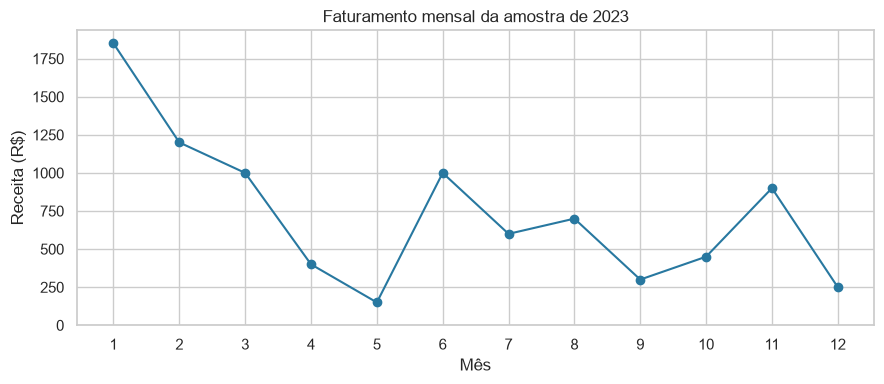

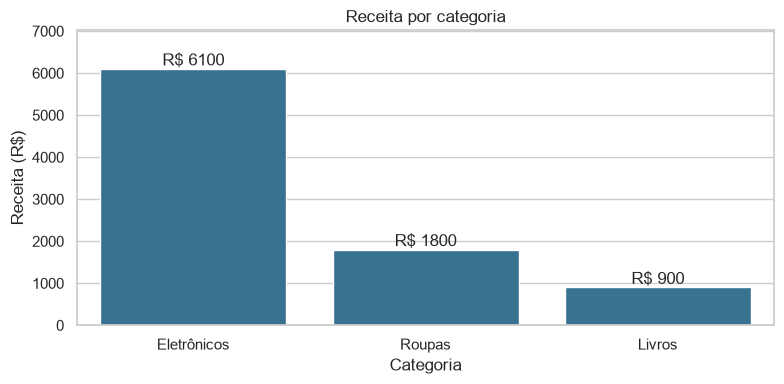

In [4]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mensal.index, mensal.values, marker='o', color='#2878a0')
ax.set(title='Faturamento mensal da amostra de 2023', xlabel='Mês', ylabel='Receita (R$)')
ax.set_xticks(range(1, 13))
ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig('vendas_mensais.png', dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=categorias.index, y=categorias.values, color='#2878a0', ax=ax)
ax.set(title='Receita por categoria', xlabel='Categoria', ylabel='Receita (R$)')
for barra in ax.patches:
    ax.annotate(f'R$ {barra.get_height():.0f}',
                (barra.get_x() + barra.get_width()/2, barra.get_height()),
                ha='center', va='bottom')
ax.set_ylim(0, categorias.max() * 1.15)
fig.tight_layout()
fig.savefig('vendas_categorias.png', dpi=180)
plt.show()

## Conferência e registro dos resultados

In [5]:
assert len(df_vendas) == 14 and round(total, 2) == 8800.00
assert categorias.to_dict() == {'Eletrônicos': 6100.0, 'Roupas': 1800.0, 'Livros': 900.0}
assert mensal.idxmax() == 1 and mensal.idxmin() == 5
print('TESTES: 14 registros, valores válidos e totais conferidos.')
with open('resultados.json', 'w', encoding='utf-8') as arquivo:
    json.dump({'total': total, 'vendas': 14, 'ticket': ticket,
               'categorias': categorias.to_dict(), 'mensal': mensal.to_dict(),
               'participacao': participacao.to_dict()}, arquivo, ensure_ascii=False, indent=2)

TESTES: 14 registros, valores válidos e totais conferidos.
